In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
import torch

In [4]:
class SubclassCancerDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        self.classes = []

        main_folders = [f for f in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, f))]
        
        for main_folder in main_folders:
            main_path = os.path.join(root_dir, main_folder)
            
            sub_folders = [f for f in os.listdir(main_path) if os.path.isdir(os.path.join(main_path, f))]
            
            for sub_folder in sub_folders:
                if sub_folder not in self.classes:
                    self.classes.append(sub_folder)
                
                sub_path = os.path.join(main_path, sub_folder)
                for img_name in os.listdir(sub_path):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(sub_path, img_name))
                        
        self.classes = sorted(self.classes)
        self.labels = [self.classes.index(os.path.basename(os.path.dirname(p))) for p in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [5]:
data_dir = '/kaggle/input/datasets/obulisainaren/multi-cancer/Multi Cancer/Multi Cancer' 

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = SubclassCancerDataset(root_dir=data_dir, transform=data_transforms)

print(f"Total images found: {len(full_dataset)}")
print(f"Number of subclasses (classes): {len(full_dataset.classes)}")
print(f"Classes list: {full_dataset.classes}")

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

Total images found: 130002
Number of subclasses (classes): 26
Classes list: ['all_benign', 'all_early', 'all_pre', 'all_pro', 'brain_glioma', 'brain_menin', 'brain_tumor', 'breast_benign', 'breast_malignant', 'cervix_dyk', 'cervix_koc', 'cervix_mep', 'cervix_pab', 'cervix_sfi', 'colon_aca', 'colon_bnt', 'kidney_normal', 'kidney_tumor', 'lung_aca', 'lung_bnt', 'lung_scc', 'lymph_cll', 'lymph_fl', 'lymph_mcl', 'oral_normal', 'oral_scc']


In [6]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

model = models.densenet169(weights=models.DenseNet169_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False

num_features = model.classifier.in_features
num_classes = len(full_dataset.classes) 
model.classifier = nn.Linear(num_features, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

print("Model architecture is ready and moved to GPU.")

Training on device: cuda
Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 97.6MB/s]


Model architecture is ready and moved to GPU.


In [7]:
import time
import copy
from tqdm import tqdm 

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    since = time.time()
    
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  
                dataloader = train_loader
            else:
                model.eval()   
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in tqdm(dataloader, desc=phase):
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()


                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
                torch.save(model.state_dict(), '/kaggle/working/best_model_phase1.pth')
                print('--- Best model saved! ---')

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    model.load_state_dict(best_model_wts)
    return model

In [8]:
model = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=3)

Epoch 1/3
----------


train: 100%|██████████| 3251/3251 [55:11<00:00,  1.02s/it] 


train Loss: 0.2904 Acc: 0.9016


val: 100%|██████████| 813/813 [13:36<00:00,  1.00s/it]


val Loss: 0.1633 Acc: 0.9369
--- Best model saved! ---

Epoch 2/3
----------


train: 100%|██████████| 3251/3251 [07:21<00:00,  7.36it/s]


... (3 outputs left out)

train: 100%|██████████| 3251/3251 [07:20<00:00,  7.38it/s]


train Loss: 0.1372 Acc: 0.9474


val: 100%|██████████| 813/813 [01:44<00:00,  7.75it/s]

val Loss: 0.1197 Acc: 0.9550

Training complete in 87m 2s
Best val Acc: 0.955117


In [10]:
for param in model.features.denseblock4.parameters():
    param.requires_grad = True

for param in model.features.norm5.parameters():
    param.requires_grad = True


print("Layers to be trained in Phase 2:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

optimizer_phase2 = torch.optim.Adam([
    {'params': model.features.denseblock4.parameters(), 'lr': 1e-5},
    {'params': model.features.norm5.parameters(), 'lr': 1e-5},
    {'params': model.classifier.parameters(), 'lr': 1e-4}
])

print("\nStarting Phase 2 Fine-tuning...")
model = train_model(model, train_loader, val_loader, criterion, optimizer_phase2, num_epochs=2)

torch.save(model.state_dict(), '/kaggle/working/final_densenet169.pth')
print("Final model saved successfully!")

Layers to be trained in Phase 2:
features.denseblock4.denselayer1.norm1.weight
features.denseblock4.denselayer1.norm1.bias
features.denseblock4.denselayer1.conv1.weight
features.denseblock4.denselayer1.norm2.weight
features.denseblock4.denselayer1.norm2.bias
features.denseblock4.denselayer1.conv2.weight
features.denseblock4.denselayer2.norm1.weight
features.denseblock4.denselayer2.norm1.bias
features.denseblock4.denselayer2.conv1.weight
features.denseblock4.denselayer2.norm2.weight
features.denseblock4.denselayer2.norm2.bias
features.denseblock4.denselayer2.conv2.weight
features.denseblock4.denselayer3.norm1.weight
features.denseblock4.denselayer3.norm1.bias
features.denseblock4.denselayer3.conv1.weight
features.denseblock4.denselayer3.norm2.weight
features.denseblock4.denselayer3.norm2.bias
features.denseblock4.denselayer3.conv2.weight
features.denseblock4.denselayer4.norm1.weight
features.denseblock4.denselayer4.norm1.bias
features.denseblock4.denselayer4.conv1.weight
features.denseb

train: 100%|██████████| 3251/3251 [09:00<00:00,  6.01it/s]


train Loss: 0.0683 Acc: 0.9760


val: 100%|██████████| 813/813 [01:47<00:00,  7.56it/s]


val Loss: 0.0363 Acc: 0.9870
--- Best model saved! ---

Epoch 2/2
----------


train: 100%|██████████| 3251/3251 [09:00<00:00,  6.02it/s]


train Loss: 0.0312 Acc: 0.9905


val: 100%|██████████| 813/813 [01:49<00:00,  7.39it/s]


val Loss: 0.0276 Acc: 0.9906
--- Best model saved! ---

Training complete in 21m 39s
Best val Acc: 0.990577
Final model saved successfully!


Generating predictions on validation set...

Classification Report:
                  precision    recall  f1-score   support

      all_benign       1.00      1.00      1.00      1028
       all_early       1.00      1.00      1.00      1006
         all_pre       1.00      1.00      1.00      1005
         all_pro       1.00      1.00      1.00       963
    brain_glioma       1.00      0.99      1.00       993
     brain_menin       0.98      1.00      0.99       954
     brain_tumor       1.00      0.99      1.00      1005
   breast_benign       1.00      0.99      0.99      1068
breast_malignant       0.99      1.00      0.99       975
      cervix_dyk       1.00      1.00      1.00       996
      cervix_koc       1.00      1.00      1.00      1024
      cervix_mep       1.00      1.00      1.00      1008
      cervix_pab       1.00      1.00      1.00      1049
      cervix_sfi       1.00      1.00      1.00       979
       colon_aca       1.00      1.00      1.00      1005
   

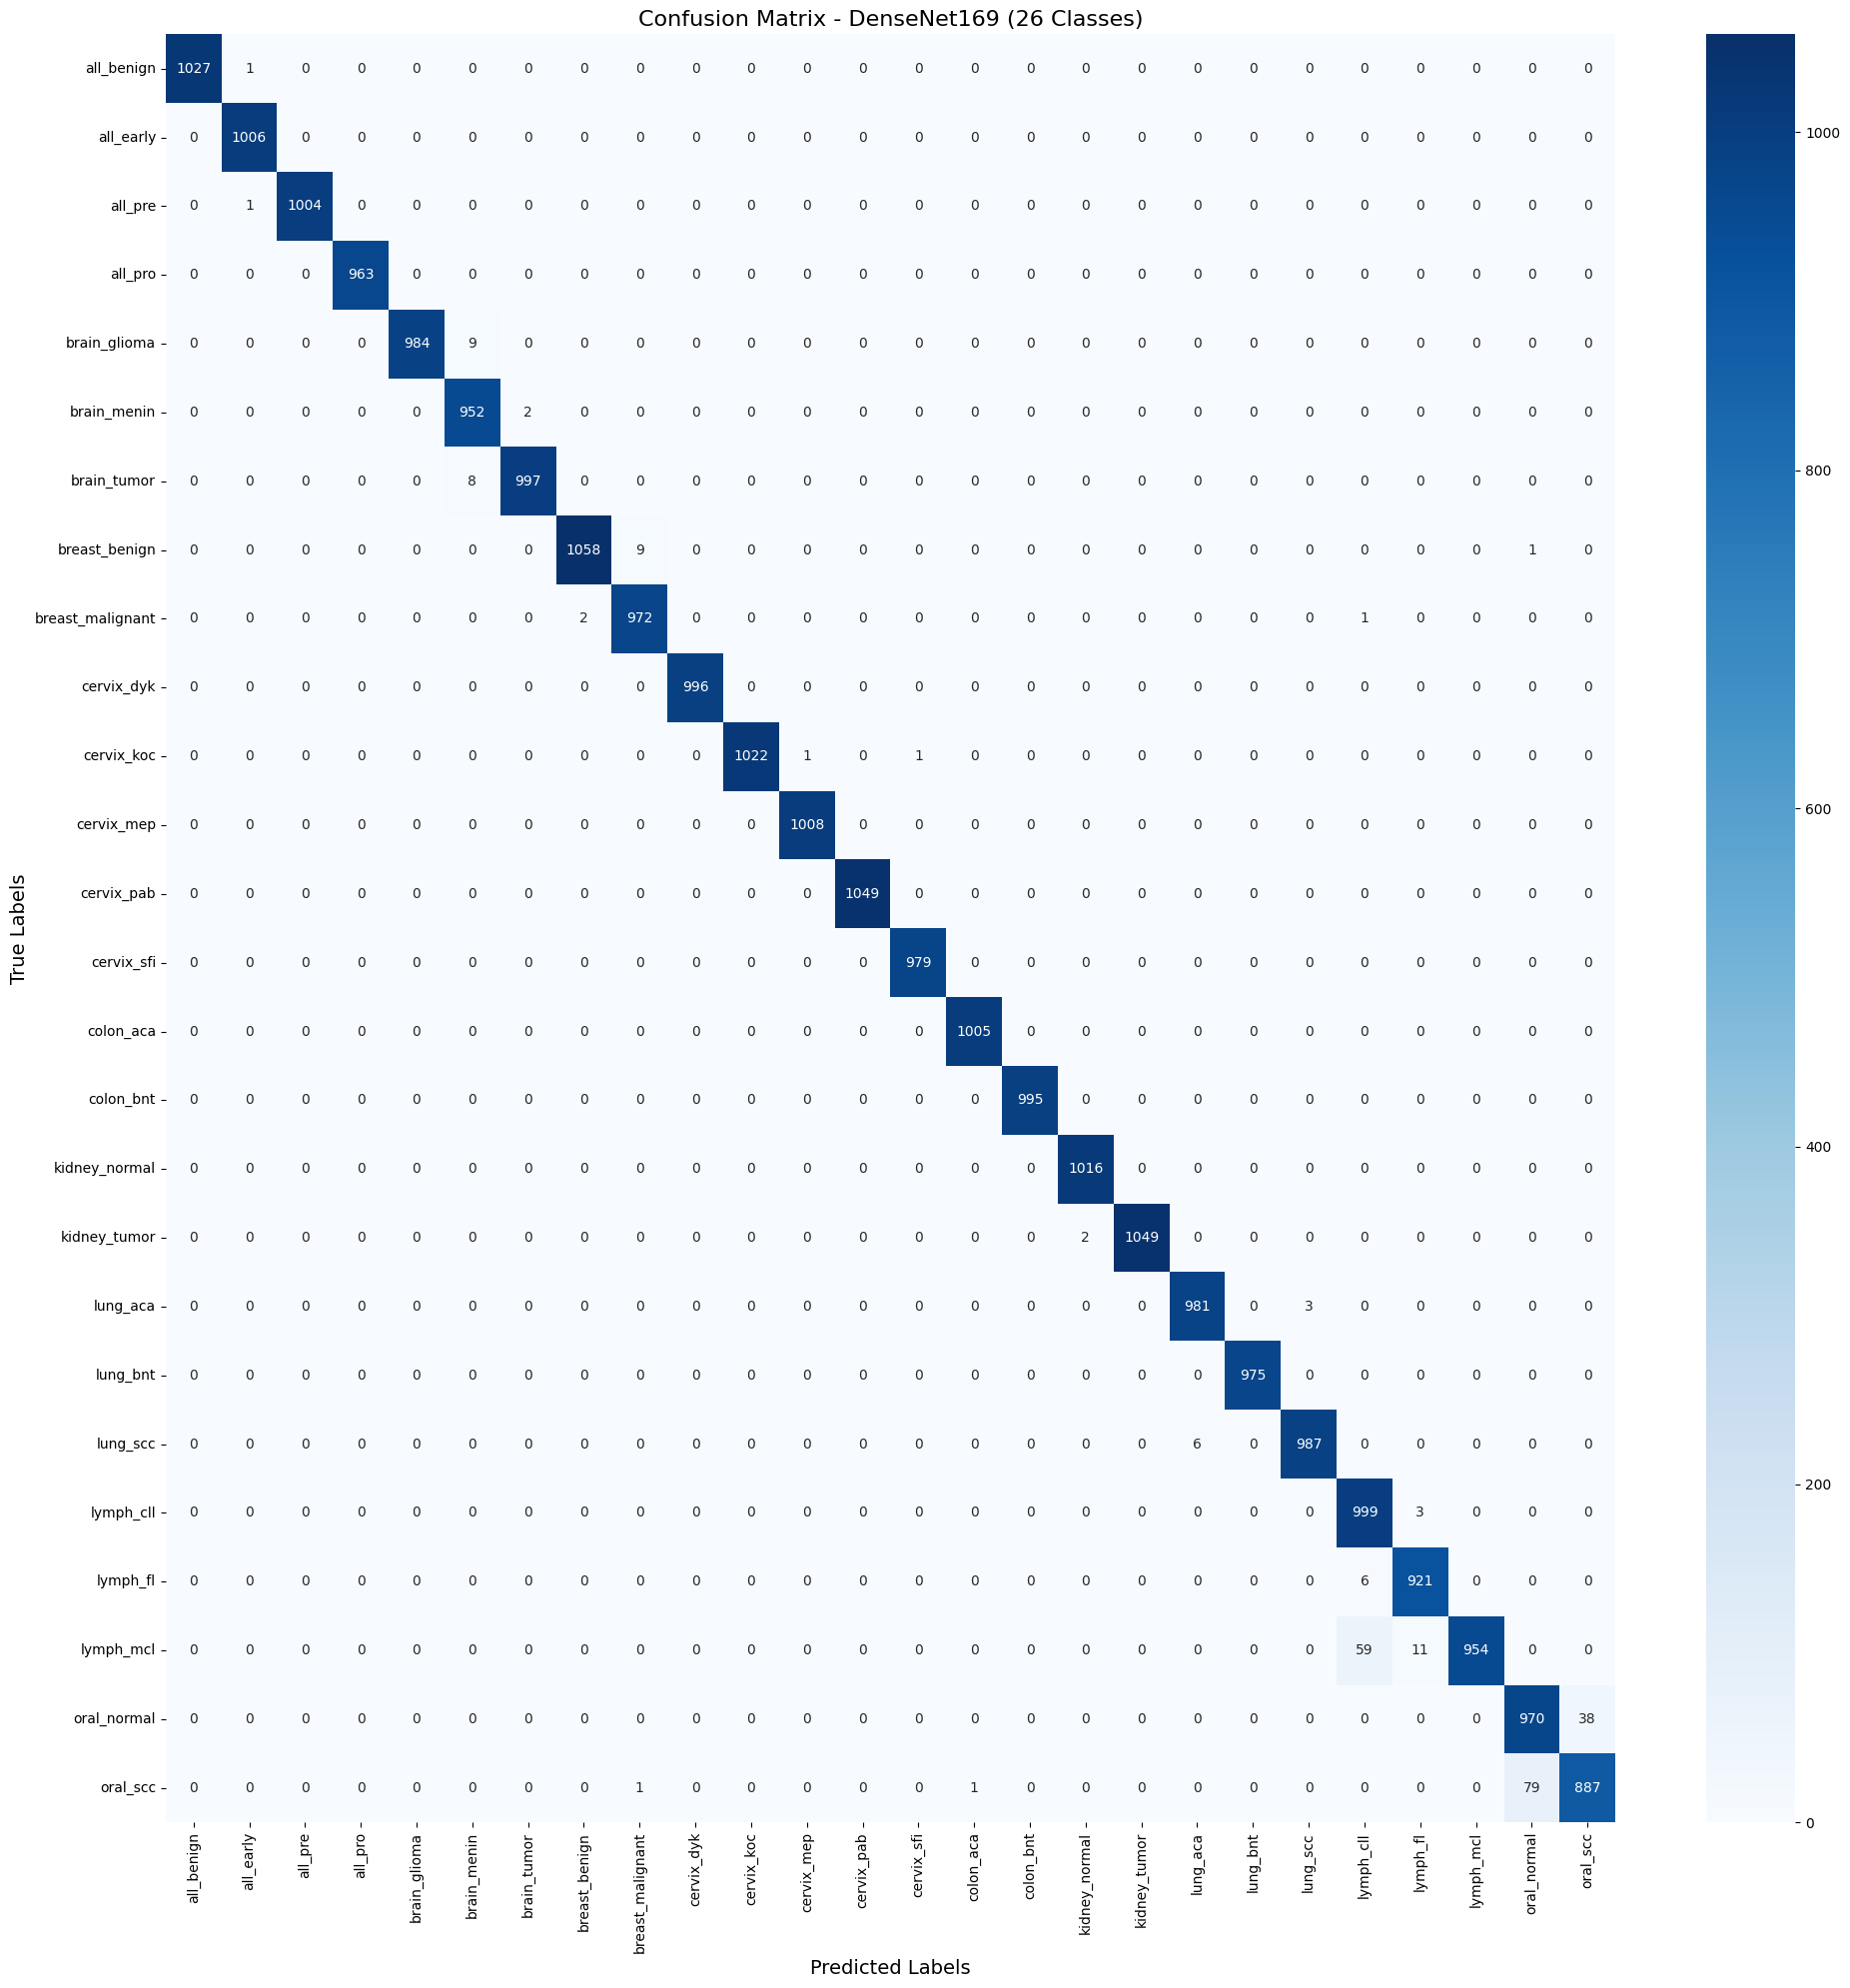

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

model.eval()

all_preds = []
all_labels = []

print("Generating predictions on validation set...")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = full_dataset.classes

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(20, 20)) 
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Labels', fontsize=14)
plt.ylabel('True Labels', fontsize=14)
plt.title('Confusion Matrix - DenseNet169 (26 Classes)', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

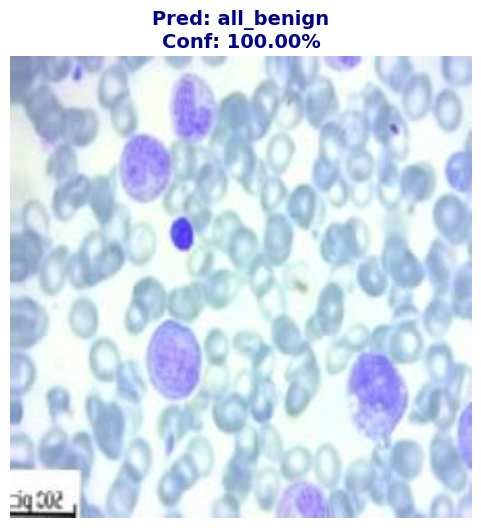

Model is 100.00% sure this is 'all_benign'.


In [13]:
import torch.nn.functional as F

def predict_single_image(image_path, model, class_names, device):
    inference_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    image = Image.open(image_path).convert('RGB')
    image_tensor = inference_transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)
        top_prob, top_class_idx = torch.max(probabilities, 1)
        
        predicted_class = class_names[top_class_idx.item()]
        confidence = top_prob.item() * 100
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f"Pred: {predicted_class}\nConf: {confidence:.2f}%", fontsize=14, fontweight='bold', color='darkblue')
    plt.show()
    
    return predicted_class, confidence
sample_image_path = full_dataset.image_paths[0] 
class_names = full_dataset.classes
pred, conf = predict_single_image(sample_image_path, model, class_names, device)

print(f"Model is {conf:.2f}% sure this is '{pred}'.")